# Data example: FRED `TCU`

U.S. monthly capacity utilization (FRED series `TCU`), fitted with an AR(1)
model to obtain a persistence level for the simulation study.


In [6]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.regression import yule_walker
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss


from ar1_model import AR1Gaussian

rng = np.random.default_rng(0)

## Data loading

Level series from `data/TCU_levels.csv` (`observation_date`, `TCU`).


In [2]:
df = pd.read_csv("data/TCU_levels.csv", parse_dates=["observation_date"])
df = df.sort_values("observation_date").reset_index(drop=True)
df.head()

,observation_date,TCU
0,1967-01-01,89.3902
1,1967-02-01,87.9750
2,1967-03-01,87.0835
3,1967-04-01,87.5089
4,1967-05-01,86.3566


In [3]:
# sanity checks: full range, gaps, duplicates, missing values
print("range:", df["observation_date"].min().date(), "to", df["observation_date"].max().date())
print("n obs:", len(df))
print("duplicated dates:", df["observation_date"].duplicated().sum())
print("missing TCU:", df["TCU"].isna().sum())

gaps = df["observation_date"].diff().dt.days
print("non-monthly gaps (>31d):", (gaps > 31).sum())

df["TCU"].describe()

range: 1967-01-01 to 2026-06-01
n obs: 714
duplicated dates: 0
missing TCU: 0
non-monthly gaps (>31d): 0


count    714.000000
mean      79.814676
std        4.217419
min       64.084700
25%       76.849525
50%       79.773750
75%       82.988425
max       89.390200
Name: TCU, dtype: float64

## Window selection

Selected window avoiding the 2009 financial crisis and the COVID-19 shock.


In [4]:
START = "2010-01-01"
END = "2019-12-01"

window = df[(df["observation_date"] >= START) & (df["observation_date"] <= END)].reset_index(drop=True)

n = len(window)
y = window["TCU"].astype(float).values
print(f"window: {START} to {END}, n = {n} ({n / 12:.1f} years)")

window: 2010-01-01 to 2019-12-01, n = 120 (10.0 years)


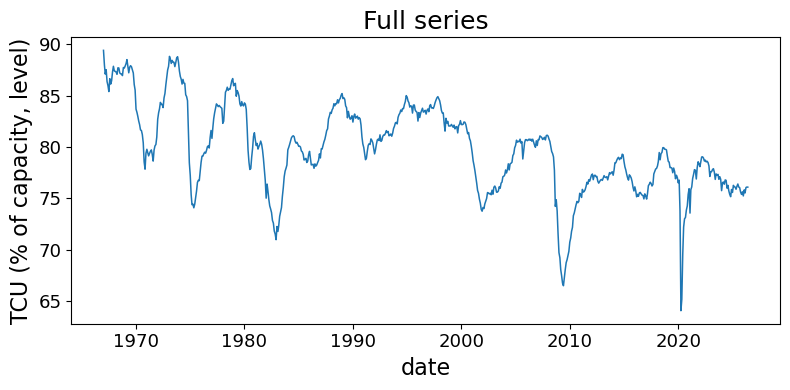

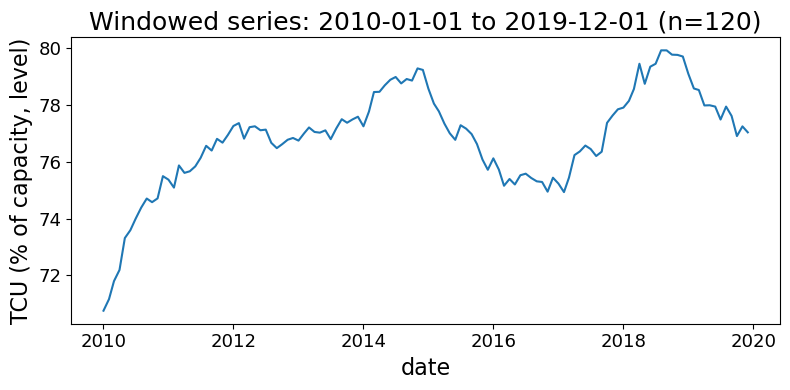

In [7]:
fig, axes = plt.subplots(1, 1, figsize=(8, 4))
axes.plot(df["observation_date"], df["TCU"], linewidth=1.1)
axes.set_xlabel("date", fontsize=16)
axes.set_ylabel("TCU (% of capacity, level)", fontsize=16)
axes.tick_params(axis='both', labelsize=13)
axes.set_title("Full series", fontsize=18)
fig.tight_layout()
fig.savefig("tcu_data_full.pdf")
plt.show()

fig, axes = plt.subplots(1, 1, figsize=(8, 4))
axes.plot(window["observation_date"], window["TCU"], linewidth=1.5)
axes.set_xlabel("date", fontsize=16)
axes.set_ylabel("TCU (% of capacity, level)", fontsize=16)
axes.tick_params(axis='both', labelsize=13)
axes.xaxis.set_major_locator(mdates.YearLocator(2))
axes.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes.set_title(f"Windowed series: {START} to {END} (n={n})", fontsize=18)
fig.tight_layout()
fig.savefig("tcu_data_window.pdf")
plt.show()

### ACF / PACF of the windowed series

Bands are statsmodels' default white-noise Bartlett bands ($\pm 1.96/\sqrt n$),
not persistence-aware; shown for exploration only, not as a confidence statement.


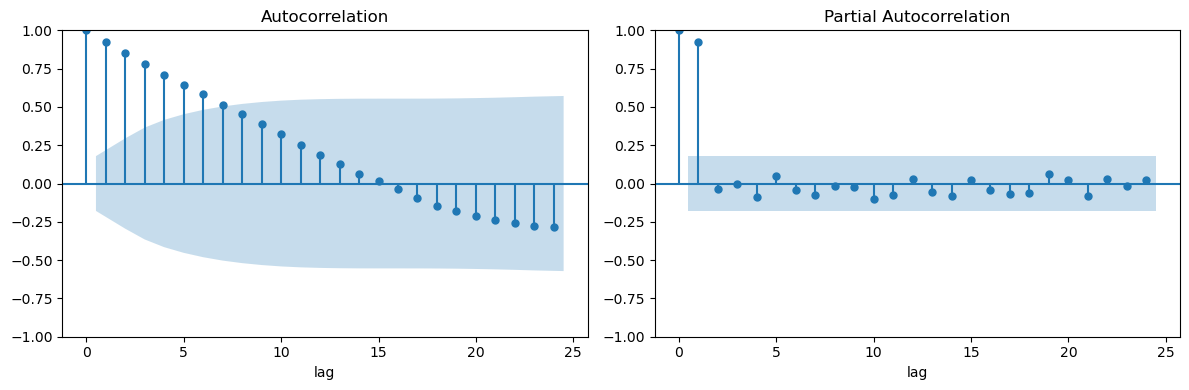

In [9]:
nlags = 24

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(y, lags=nlags, ax=axes[0])
plot_pacf(y, lags=nlags, method="ywm", ax=axes[1])
axes[0].set_xlabel("lag")
axes[1].set_xlabel("lag")
fig.tight_layout()

### ADF / KPSS

Computed on the windowed series.


In [14]:
adf_stat, adf_pvalue, *_ = adfuller(y, regression="c", autolag="AIC")

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=InterpolationWarning)
    kpss_stat, kpss_pvalue, *_ = kpss(y, regression="c", nlags="auto")

print(f"ADF:  stat={adf_stat:.4f}, p={adf_pvalue:.4f}  (H0: unit root)")
print(f"KPSS: stat={kpss_stat:.4f}, p={kpss_pvalue:.4f}  (H0: stationary)")

ADF:  stat=-2.4334, p=0.1325  (H0: unit root)
KPSS: stat=0.3717, p=0.0893  (H0: stationary)


ADF does not reject a unit root; KPSS rejects stationarity. Neither is decisive
at this persistence: ADF has low power against near-unit-root stationary
alternatives (Elliott et al., 1996), and KPSS-type tests over-reject a true
stationarity null for highly persistent processes (Caner & Kilian, 2001).
We quantify this unreliability at the end of this notebook.


## Fitting an AR(1) model

Three estimators: OLS, Yule-Walker, exact Gaussian MLE.


In [17]:
ols_model = AutoReg(y, lags=1, trend="c").fit()
alpha_ols = ols_model.params[1]  # params = [const, lag1]
resid_ols = ols_model.resid  # length n-1; kept for OLS diagnostics and MLE starting values

rho, _ = yule_walker(y, order=1, method="mle")  # divisor n, not n-k
alpha_yw = rho[0]

mle_model = ARIMA(y, order=(1, 0, 0), trend="c").fit()
resid_mle = mle_model.resid
alpha_mle = mle_model.arparams[0]

print(f"OLS:  alpha_hat = {alpha_ols:.4f}")
print(f"YW:   alpha_hat = {alpha_yw:.4f}")
print(f"MLE:  alpha_hat = {alpha_mle:.4f}")

OLS:  alpha_hat = 0.9256
YW:   alpha_hat = 0.9254
MLE:  alpha_hat = 0.9919


OLS and Yule-Walker agree closely; both diverge substantially from MLE.
Checking MLE convergence:


In [18]:
print(mle_model.mle_retvals)  # convergence flag, iterations, gradient at optimum

for start_ar in [0.5, 0.7, 0.9, 0.95, 0.99]:
    m = ARIMA(y, order=(1, 0, 0), trend="c").fit(start_params=[y.mean(), start_ar, np.var(resid_ols)])
    print(
        f"start={start_ar}: alpha={m.arparams[0]:.4f}, llf={m.llf:.3f}, "
        f"converged={m.mle_retvals.get('converged', 'n/a')}"
    )

{'fopt': np.float64(0.46241736327234123), 'gopt': array([-2.82862067e-06, -1.80022663e-08,  9.91102755e-06]), 'fcalls': 108, 'warnflag': 0, 'converged': True, 'iterations': 22}
start=0.5: alpha=0.9919, llf=-55.490, converged=True
start=0.7: alpha=0.9919, llf=-55.490, converged=True
start=0.9: alpha=0.9919, llf=-55.490, converged=True
start=0.95: alpha=0.9919, llf=-55.490, converged=True
start=0.99: alpha=0.9919, llf=-55.490, converged=True


Identical estimates and near-zero gradient from all five starting values:
MLE has converged to a genuine optimum, not a local artifact.


In [19]:
alpha_hat = alpha_mle

v_hat = 1 - alpha_hat
print(f"alpha_hat   = {alpha_hat:.4f}")
print(f"v_hat       = {v_hat:.4f}")
print(f"n           = {n}")
print(f"n*v_hat     = {n * v_hat:.3f}")

alpha_hat   = 0.9919
v_hat       = 0.0081
n           = 120
n*v_hat     = 0.968


### Residual diagnostics

Uses `resid_mle`. The first residual reflects Kalman-filter initial state prediction, not the data, and is dropped once at definition.


In [20]:
resid = resid_mle[1:]  # drop the initial-state prediction residual

      lb_stat  lb_pvalue
10  23.653977   0.004883
20  32.297580   0.028926


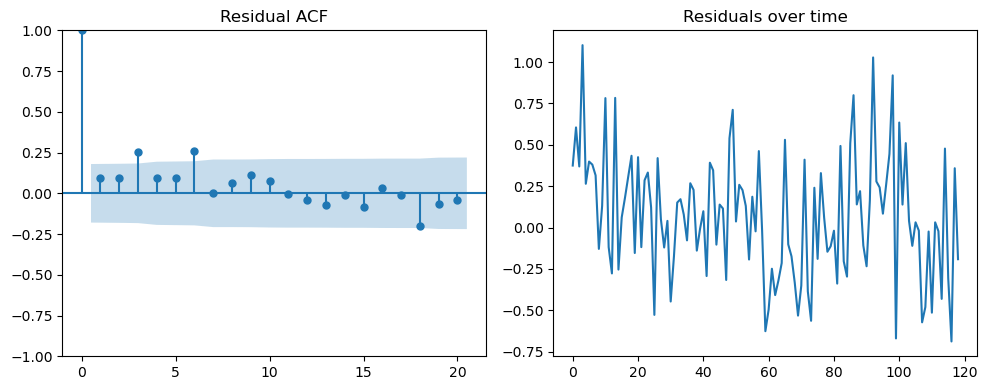

In [21]:
lb = acorr_ljungbox(resid, lags=[10, 20], model_df=1, return_df=True)
print(lb)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(resid, lags=20, ax=axes[0])
axes[0].set_title("Residual ACF")
axes[1].plot(resid)
axes[1].set_title("Residuals over time")
plt.tight_layout()
plt.show()

Ljung-Box rejects at both lags 10 and 20 (remaining serial dependence in the
residuals).

### Normality

Jarque-Bera checks skewness/kurtosis against a normal distribution;
Shapiro-Wilk is more general and better-calibrated here, though it assumes
an iid sample (approximate for model residuals).


skewness         = 0.255
excess kurtosis  = -0.142
Jarque-Bera stat = 1.393, p = 0.4984
Shapiro-Wilk: stat=0.9899, p=0.5361


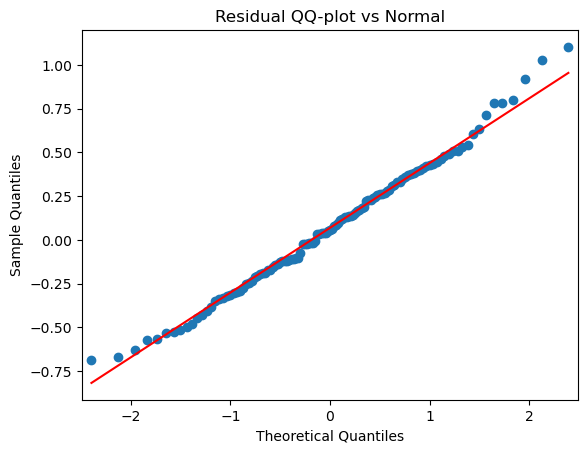

In [22]:
skew = stats.skew(resid)
exkurt = stats.kurtosis(resid)  # excess kurtosis, Fisher convention (0 = normal)
jb_stat, jb_p = stats.jarque_bera(resid)
sw_stat, sw_p = stats.shapiro(resid)

print(f"skewness         = {skew:.3f}")
print(f"excess kurtosis  = {exkurt:.3f}")
print(f"Jarque-Bera stat = {jb_stat:.3f}, p = {jb_p:.4f}")
print(f"Shapiro-Wilk: stat={sw_stat:.4f}, p={sw_p:.4f}")

sm.qqplot(resid, line="s")
plt.title("Residual QQ-plot vs Normal")
plt.show()

In [23]:
nu_hat, loc_hat, scale_hat = stats.t.fit(resid)
print(f"Fitted Student-t: nu={nu_hat:.2f}, loc={loc_hat:.4f}, scale={scale_hat:.4f}")

if nu_hat > 4:
    implied_kurt = 6 / (nu_hat - 4)
    print(f"implied excess kurtosis: {implied_kurt:.3f}  (empirical: {exkurt:.3f})")

Fitted Student-t: nu=16287476407.88, loc=0.0687, scale=0.3699
implied excess kurtosis: 0.000  (empirical: -0.142)


$\hat\nu$ is extremely large - the $t$-fit hitting the boundary of the family
as $\nu\to\infty$ ($t_\nu\to\mathcal N$), a numerical artifact of a
near-Gaussian sample rather than a meaningful degrees-of-freedom estimate.


In [24]:
arch_stat_ols, arch_p_ols, _, _ = het_arch(resid_ols, nlags=10)
arch_stat_mle, arch_p_mle, _, _ = het_arch(resid, nlags=10)
print(f"OLS residuals: ARCH-LM p = {arch_p_ols:.4f}")
print(f"MLE residuals: ARCH-LM p = {arch_p_mle:.4f}")

OLS residuals: ARCH-LM p = 0.1756
MLE residuals: ARCH-LM p = 0.0233


### ADF/KPSS under the fitted model

Fraction of simulated stationary AR(1) paths, at persistence
$\alpha \in \{0.3, 0.6, 0.85, \hat\alpha\}$, producing ADF/KPSS statistics
at least as extreme as those observed.


In [25]:
sigma2_idx = list(mle_model.param_names).index("sigma2")
sigma2_hat = mle_model.params[sigma2_idx]

R_test = 10_000

for a in [0.3, 0.6, 0.85, alpha_hat]:
    m = AR1Gaussian(n, a, kappa_2=sigma2_hat, k=1)
    samp = m.sample_paths(R_test, rng)
    adf_p = np.array([adfuller(x, regression="c")[0] for x in samp])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=InterpolationWarning)
        kpss_p = np.array([kpss(x, regression="c", nlags="auto")[0] for x in samp])
    print(
        f"alpha={a:.3f}: P(ADF>=obs)={np.mean(adf_p >= adf_stat):.3f}, "
        f"P(KPSS>=obs)={np.mean(kpss_p >= kpss_stat):.3f}"
    )

alpha=0.300: P(ADF>=obs)=0.006, P(KPSS>=obs)=0.119
alpha=0.600: P(ADF>=obs)=0.011, P(KPSS>=obs)=0.170
alpha=0.850: P(ADF>=obs)=0.082, P(KPSS>=obs)=0.362
alpha=0.992: P(ADF>=obs)=0.836, P(KPSS>=obs)=0.827
